# Demo 3 · PCA: un mapa de posicionamiento de autos

**La pregunta de negocio.** Trabajamos en una automotriz y queremos ver **cómo están posicionados los modelos del mercado**: ¿dónde hay mucha competencia?, ¿hay huecos? Tenemos 12 características técnicas por modelo, pero no podemos graficar 12 dimensiones.

PCA resume muchas variables correlacionadas en **pocas variables nuevas** (componentes principales) que conservan la mayor parte de la información. Con 2 componentes podemos hacer un mapa.

**Dataset:** *Cars93* (93 modelos de autos vendidos en EE.UU., paquete `MASS` de R).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
pd.set_option("display.precision", 2)
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
autos = pd.read_csv("data/autos_cars93.csv")
nombres = {"Price": "precio", "MPG.city": "rend_ciudad", "MPG.highway": "rend_ruta",
           "EngineSize": "motor_litros", "Horsepower": "potencia", "RPM": "rpm_max",
           "Fuel.tank.capacity": "tanque", "Passengers": "pasajeros", "Length": "largo",
           "Wheelbase": "dist_ejes", "Width": "ancho", "Weight": "peso"}
X = autos[list(nombres)].rename(columns=nombres)
X.index = autos.Make
X.head()

,precio,rend_ciudad,rend_ruta,motor_litros,potencia,rpm_max,tanque,pasajeros,largo,dist_ejes,ancho,peso
Make,,,,,,,,,,,,
Acura Integra,15.9,25,31,1.8,140,6300,13.2,5,177,102,68,2705
Acura Legend,33.9,18,25,3.2,200,5500,18.0,5,195,115,71,3560
Audi 90,29.1,20,26,2.8,172,5500,16.9,5,180,102,67,3375
Audi 100,37.7,19,26,2.8,172,5500,21.1,6,193,106,70,3405
BMW 535i,30.0,22,30,3.5,208,5700,21.1,4,186,109,69,3640


## 1. El problema: muchas variables que dicen lo mismo

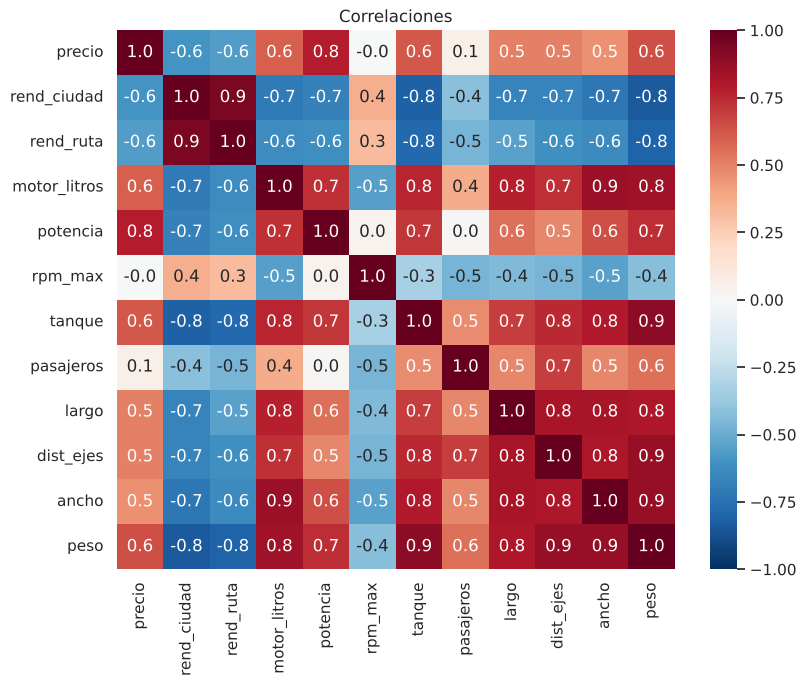

In [3]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(X.corr(), annot=True, fmt=".1f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlaciones");

Peso, largo, ancho, tanque, motor... están todas muy correlacionadas (≈0.8-0.9). En el fondo todas miden **"qué tan grande es el auto"**. Y el rendimiento va en contra (rojo/azul): los autos grandes gastan más.

Esa redundancia es justamente lo que PCA aprovecha.

## 2. Intuición con 2 variables

Antes de las 12, mirá solo largo y peso. Los puntos forman una nube alargada en diagonal. PCA busca **la dirección en la que la nube se estira más** (PC1) y la usa como nuevo eje.

% de la información en cada componente: [90.3  9.7]


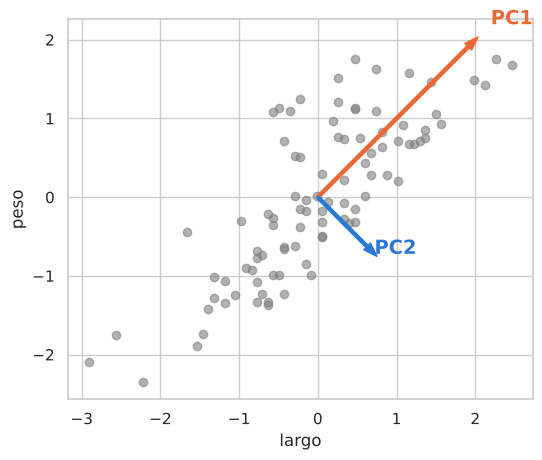

In [4]:
xy = StandardScaler().fit_transform(X[["largo", "peso"]])
p2 = PCA(n_components=2).fit(xy)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(xy[:, 0], xy[:, 1], alpha=0.6, color="gray")
for vec, var, col, nom in zip(p2.components_, p2.explained_variance_, [PAL[1], PAL[0]], ["PC1", "PC2"]):
    v = vec * 2 * np.sqrt(var)
    ax.arrow(0, 0, *v, width=0.04, color=col)
    ax.text(*(v * 1.15), nom, color=col, fontsize=14, weight="bold")
ax.set_aspect("equal"); ax.set_xlabel("largo"); ax.set_ylabel("peso")

print("% de la información en cada componente:", (p2.explained_variance_ratio_ * 100).round(1))

Con **un solo número** (la posición sobre PC1) conservamos ~90% de la información de largo y peso. Ese número es básicamente el **"tamaño"** del auto.

## 3. Ahora con las 12 variables

Como siempre, primero estandarizamos (si no, el precio en dólares o el peso en libras dominarían todo).

In [5]:
X_esc = StandardScaler().fit_transform(X)
pca = PCA()
componentes = pca.fit_transform(X_esc)

var = pd.DataFrame({
    "% varianza": pca.explained_variance_ratio_ * 100,
    "% acumulado": pca.explained_variance_ratio_.cumsum() * 100,
}, index=[f"PC{i+1}" for i in range(12)])
var.head(6)

,% varianza,% acumulado
PC1,65.74,65.74
PC2,13.93,79.67
PC3,6.31,85.98
PC4,5.00,90.97
PC5,2.87,93.84
PC6,2.11,95.95


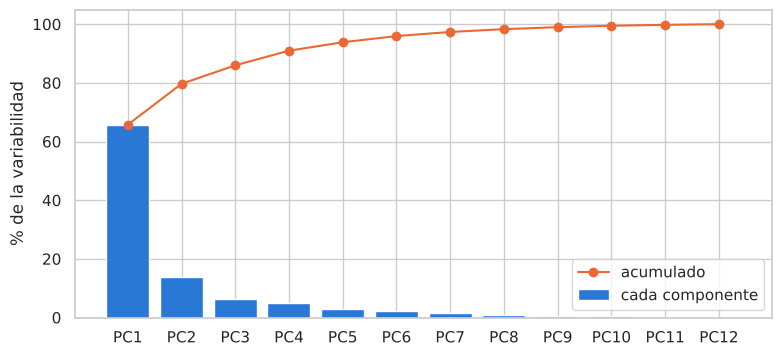

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(var.index, var["% varianza"], color=PAL[0], label="cada componente")
ax.plot(var.index, var["% acumulado"], marker="o", color=PAL[1], label="acumulado")
ax.set_ylabel("% de la variabilidad"); ax.legend();

**PC1 solo explica ~66%** y con **2 componentes llegamos a ~80%** de las 12 variables. Las últimas componentes casi no aportan nada.

## 4. ¿Qué significa cada componente? (loadings)

Cada componente es una **receta**: una suma ponderada de las variables originales.

$$PC1 = w_1 \cdot \text{precio} + w_2 \cdot \text{rend\_ciudad} + \dots + w_{12} \cdot \text{peso}$$

Los pesos $w$ (los *loadings*) nos dicen cómo interpretar la componente. **Esto es lo que tenemos que poner nosotros**: PCA no le pone nombre.

,PC1,PC2
precio,0.24,0.44
rend_ciudad,-0.31,-0.09
rend_ruta,-0.30,-0.08
motor_litros,0.32,0.01
potencia,0.26,0.47
rpm_max,-0.17,0.52
tanque,0.32,0.07
pasajeros,0.20,-0.49
largo,0.30,-0.10
dist_ejes,0.31,-0.19


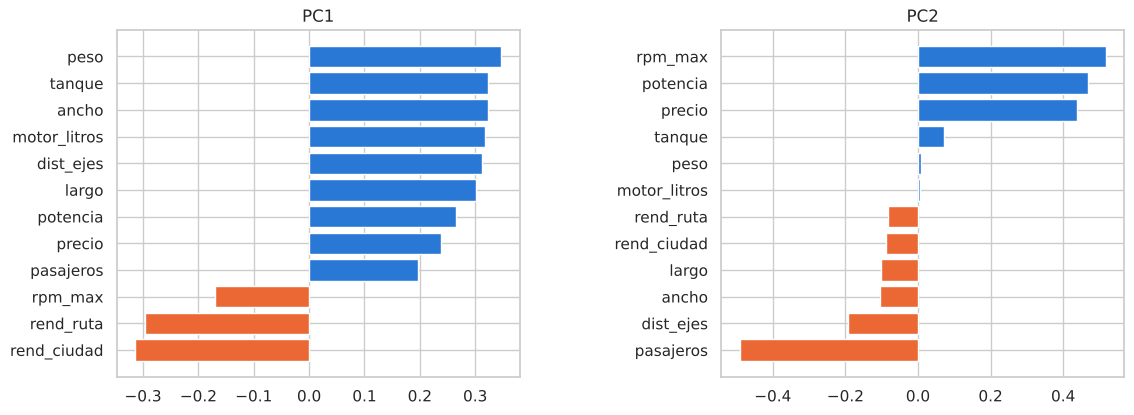

In [7]:
loadings = pd.DataFrame(pca.components_[:2].T, index=X.columns, columns=["PC1", "PC2"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"wspace": 0.5})
for ax, pc in zip(axes, ["PC1", "PC2"]):
    s = loadings[pc].sort_values()
    ax.barh(s.index, s.values, color=[PAL[1] if v < 0 else PAL[0] for v in s])
    ax.set_title(pc)
loadings.round(2)

- **PC1 = tamaño.** Todo lo que es "grande" (peso, ancho, motor, tanque) pesa positivo; el rendimiento pesa negativo. Valores altos = auto grande y gastador.
- **PC2 = deportivo/premium vs. familiar.** Potencia, RPM y precio positivos; pasajeros negativo. Valores altos = deportivo/caro y para pocas personas.

## 5. El mapa de posicionamiento

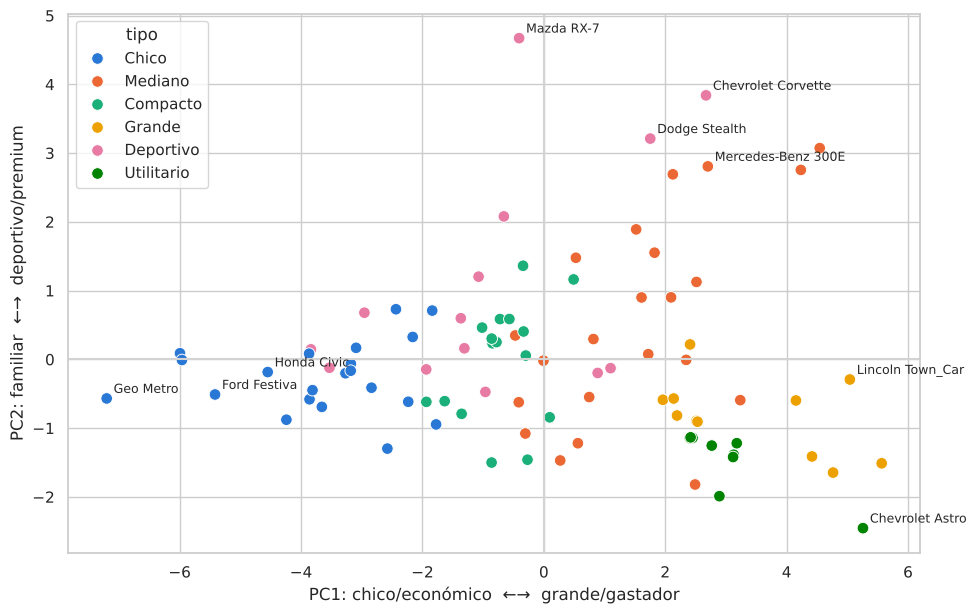

In [8]:
mapa = pd.DataFrame(componentes[:, :2], columns=["PC1", "PC2"], index=X.index)
mapa["tipo"] = autos.Type.map({"Small": "Chico", "Compact": "Compacto", "Midsize": "Mediano",
                               "Large": "Grande", "Sporty": "Deportivo", "Van": "Utilitario"}).values

fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(data=mapa, x="PC1", y="PC2", hue="tipo", palette=PAL[:6], s=70, ax=ax)
for modelo in ["Chevrolet Corvette", "Mazda RX-7", "Geo Metro", "Chevrolet Astro", "Lincoln Town_Car",
               "Mercedes-Benz 300E", "Honda Civic", "Ford Festiva", "Dodge Stealth"]:
    ax.annotate(modelo, mapa.loc[modelo, ["PC1", "PC2"]], xytext=(5, 4), textcoords="offset points", fontsize=9)
ax.axhline(0, color="lightgray"); ax.axvline(0, color="lightgray")
ax.set_xlabel("PC1: chico/económico  ←→  grande/gastador")
ax.set_ylabel("PC2: familiar  ←→  deportivo/premium");

**El tipo de auto no lo usamos para calcular PCA**, y aun así los tipos quedan ordenados en el mapa: chicos a la izquierda, grandes y utilitarios a la derecha, deportivos arriba. Eso nos dice que las dos componentes capturan algo real.

Lecturas de negocio:
- ¿Dónde hay mucha competencia? (zona compacta/mediana, cerca del centro)
- ¿Hay huecos? (arriba a la derecha: grande **y** deportivo, casi vacío)
- ¿Quién compite con quién? Los vecinos en el mapa son competidores directos.

## 6. Bonus: PCA + clustering

PCA y clustering se combinan muy bien: primero resumimos con PCA y después agrupamos sobre las componentes. Agrupar en 2 dimensiones es más fácil de ver y de explicar.

tipo,Chico,Compacto,Deportivo,Grande,Mediano,Utilitario
cluster,,,,,,
0,0,0,3,0,9,0
1,18,0,3,0,0,0
2,0,0,0,11,4,9
3,3,16,8,0,9,0


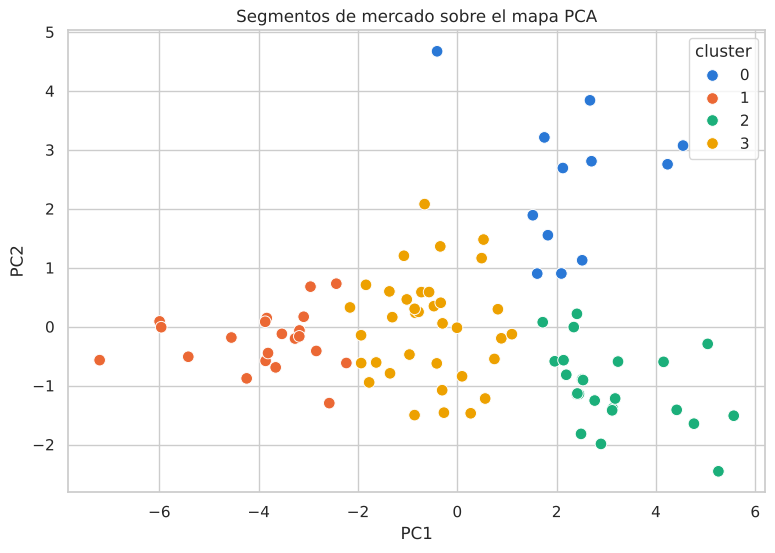

In [9]:
from sklearn.cluster import KMeans

mapa["cluster"] = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(mapa[["PC1", "PC2"]])
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=mapa, x="PC1", y="PC2", hue="cluster", palette=PAL[:4], s=70, ax=ax)
ax.set_title("Segmentos de mercado sobre el mapa PCA")
pd.crosstab(mapa.cluster, mapa.tipo)

## 7. Para pensar en clase

1. ¿Qué pasa si **no** estandarizamos? (Probá `PCA().fit(X)` y mirá los loadings: ¿qué variable domina y por qué?)
2. ¿Dónde lanzarías un modelo nuevo? Justificalo con el mapa.
3. PCA es muy útil para visualizar, pero ¿qué perdés si usás las componentes en vez de las variables originales en un modelo predictivo? (Pista: explicabilidad.)